# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / 1024**2  # 16 bits = 2 bytes per voxel; MiB convention

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x, y, z)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = 512 * 300 * 512  # x-z rays, each sampled along y
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * (1 - 0.35)

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 6,134,169,600


**Reflection:** If anisotropic voxels were displayed as cubes, the coronal and sagittal anatomy would be geometrically distorted: the z direction would be stretched or compressed relative to the in-plane direction. Distances and shapes could look wrong, which can mislead visual interpretation and measurements. The software must use the physical voxel spacing (including the correct aspect ratio) so the displayed anatomy preserves its real proportions.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

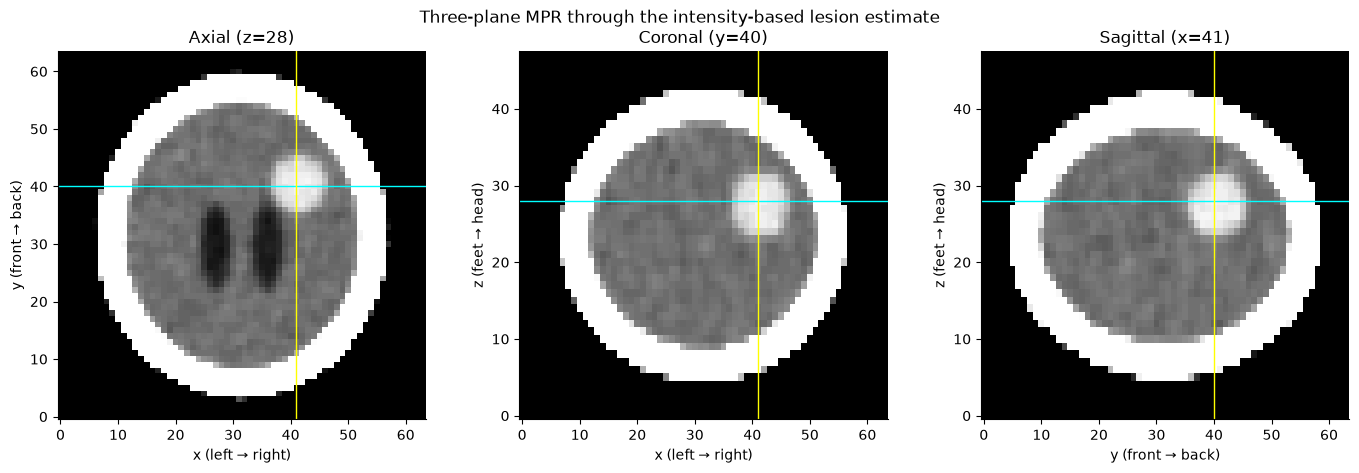

Estimated centroid (z, y, x) = (np.int64(28), np.int64(40), np.int64(41))
Reference-centroid distance (evaluation only) = 2.92 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: use intensity and an eroded intracranial mask; do not use labels to locate the lesion.
bone = vol > 300
inside = ndimage.binary_fill_holes(bone) & ~bone
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2: keep the largest connected candidate component and estimate its centroid.
components, n_components = ndimage.label(candidates)
component_sizes = np.bincount(components.ravel())
component_sizes[0] = 0
largest_component_id = int(component_sizes.argmax())
lesion = components == largest_component_id
cz, cy, cx = np.round(np.argwhere(lesion).mean(axis=0)).astype(int)

# TODO 3: linked orthogonal views through the estimated centroid.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

axes[0].imshow(window(vol[cz], 80, 40), cmap="gray", origin="lower", vmin=0, vmax=1)
axes[0].axhline(cy, color="cyan", linewidth=1)
axes[0].axvline(cx, color="yellow", linewidth=1)
axes[0].set_title(f"Axial (z={cz})")
axes[0].set_xlabel("x (left → right)"); axes[0].set_ylabel("y (front → back)")

axes[1].imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="lower", aspect=ASPECT, vmin=0, vmax=1)
axes[1].axhline(cz, color="cyan", linewidth=1)
axes[1].axvline(cx, color="yellow", linewidth=1)
axes[1].set_title(f"Coronal (y={cy})")
axes[1].set_xlabel("x (left → right)"); axes[1].set_ylabel("z (feet → head)")

axes[2].imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="lower", aspect=ASPECT, vmin=0, vmax=1)
axes[2].axhline(cz, color="cyan", linewidth=1)
axes[2].axvline(cy, color="yellow", linewidth=1)
axes[2].set_title(f"Sagittal (x={cx})")
axes[2].set_xlabel("y (front → back)"); axes[2].set_ylabel("z (feet → head)")

plt.suptitle("Three-plane MPR through the intensity-based lesion estimate")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only): compare the estimate with the held-out reference after locating it.
truth_coords = np.argwhere(labels == 5)
truth_centroid = truth_coords.mean(axis=0)
estimated_centroid = np.array([cz, cy, cx], dtype=float)
distance_mm = np.linalg.norm((estimated_centroid - truth_centroid) * np.array(SPACING))
print(f"Estimated centroid (z, y, x) = {(cz, cy, cx)}")
print(f"Reference-centroid distance (evaluation only) = {distance_mm:.2f} mm")

**Reflection:** Erosion removes the thin shell next to the skull before intensity thresholding. Because each voxel averages signal over a finite volume, a boundary voxel can mix bone, air, and brain (the partial-volume effect), producing intermediate HU values that overlap the tumour's intensity range. Without erosion, those mixed boundary voxels could become false tumour candidates. Erosion reduces this contamination, although it can also remove genuine tissue near a boundary.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_hu,voxels,volume_ml,dice_vs_truth
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


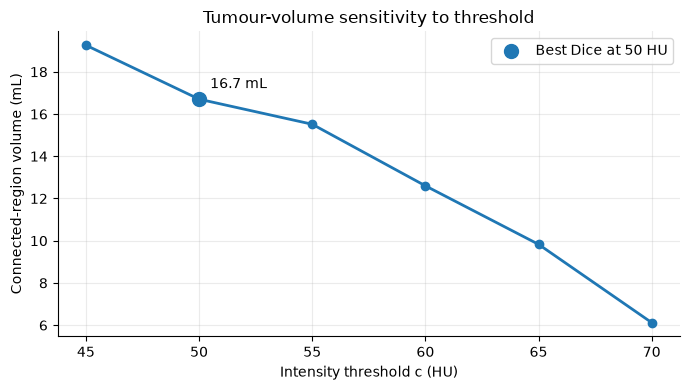

Threshold-dependent volume range: 6.1–19.3 mL
Best evaluation Dice: 0.994 at 50 HU (16.7 mL)


In [4]:
truth = labels == 5  # evaluation only; never used to locate the lesion
rows = []
for c in [45, 50, 55, 60, 65, 70]:
    components_c, _ = ndimage.label(vol > c)
    component_id = components_c[cz, cy, cx]
    region = components_c == component_id if component_id != 0 else np.zeros_like(vol, dtype=bool)
    voxel_count = int(region.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum()) if (region.sum() + truth.sum()) else 0.0
    rows.append({"threshold_hu": c, "voxels": voxel_count, "volume_ml": volume_ml, "dice_vs_truth": dice})

table = pd.DataFrame(rows).round({"volume_ml": 3, "dice_vs_truth": 3})
display(table)

# TODO 3: plot threshold sensitivity and identify the best-overlap threshold for evaluation.
best_row = table.loc[table["dice_vs_truth"].idxmax()]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold_hu"], table["volume_ml"], marker="o", linewidth=2)
ax.scatter([best_row["threshold_hu"]], [best_row["volume_ml"]], s=100, zorder=3, label=f"Best Dice at {int(best_row['threshold_hu'])} HU")
ax.annotate(f"{best_row['volume_ml']:.1f} mL", (best_row["threshold_hu"], best_row["volume_ml"]), xytext=(8, 8), textcoords="offset points")
ax.set_xlabel("Intensity threshold c (HU)")
ax.set_ylabel("Connected-region volume (mL)")
ax.set_title("Tumour-volume sensitivity to threshold")
ax.grid(alpha=0.25); ax.legend()

plt.tight_layout(); plt.show()

# TODO 4: report the range rather than implying one exact volume.
volume_min = float(table["volume_ml"].min())
volume_max = float(table["volume_ml"].max())
print(f"Threshold-dependent volume range: {volume_min:.1f}–{volume_max:.1f} mL")
print(f"Best evaluation Dice: {best_row['dice_vs_truth']:.3f} at {int(best_row['threshold_hu'])} HU ({best_row['volume_ml']:.1f} mL)")

**Reflection:** Without ground truth, I would choose a threshold using the radiologist's review of the lesion boundary on the linked MPR slices, then check whether the resulting region remains anatomically plausible across nearby thresholds. I would report the sensitivity range (here, approximately 6.1–19.3 mL) alongside the chosen estimate rather than presenting one value as exact. A small-multiple plot of volume versus threshold, plus slice contours at a low, selected, and high threshold, makes the uncertainty visible. The evaluation-only Dice score is useful for this exercise, but it would not be available in a real clinical scan.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

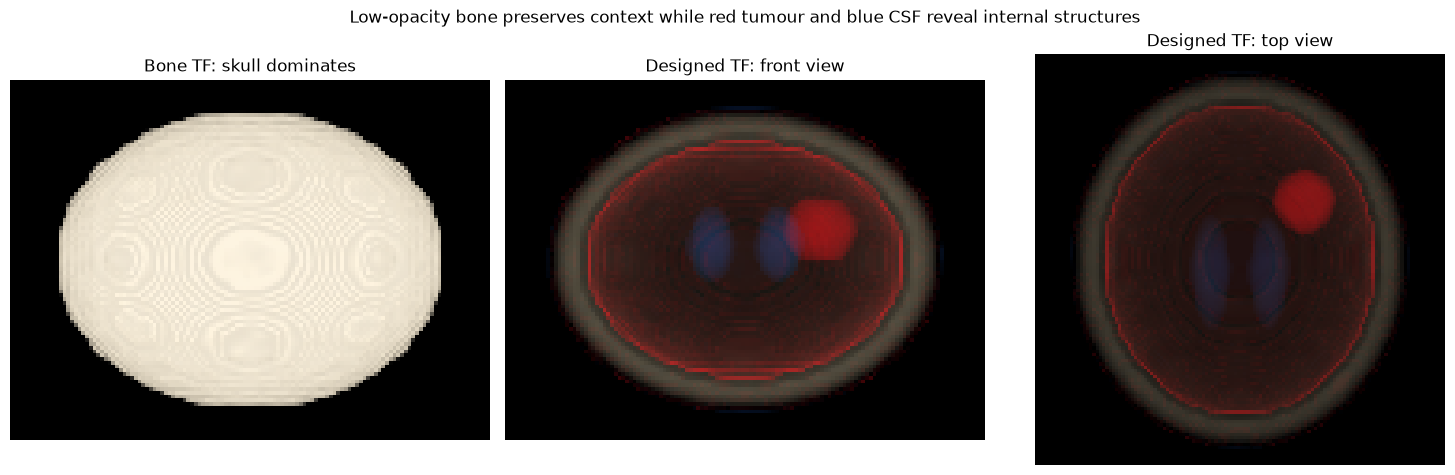

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: keep air/soft tissue transparent, show CSF faintly blue, tumour red, and bone as faint context.
tumour_tf = make_tf([
    (-1100, (0, 0, 0), 0.0),
    (0,     (0, 0, 0), 0.0),
    (5,     (0.15, 0.45, 1.0), 0.008),
    (20,    (0.15, 0.45, 1.0), 0.008),
    (22,    (0, 0, 0), 0.0),
    (45,    (0, 0, 0), 0.0),
    (48,    (1.0, 0.05, 0.08), 0.0),
    (55,    (1.0, 0.05, 0.08), 0.035),
    (75,    (1.0, 0.05, 0.08), 0.035),
    (90,    (1.0, 0.05, 0.08), 0.0),
    (200,   (0, 0, 0), 0.0),
    (300,   (0, 0, 0), 0.0),
    (400,   (0.95, 0.88, 0.72), 0.005),
    (1000,  (0.95, 0.88, 0.72), 0.01),
    (1500,  (0.95, 0.88, 0.72), 0.01)
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: compare the bone-only render with front and top views using the designed TF.
bone_front, bone_alpha = render(vol, bone_tf, axis=1)
tumour_front, tumour_front_alpha = render(vol, tumour_tf, axis=1)
tumour_top, tumour_top_alpha = render(vol, tumour_tf, axis=0)

axes[0].imshow(np.clip(bone_front, 0, 1), origin="lower")
axes[0].set_title("Bone TF: skull dominates")
axes[1].imshow(np.clip(tumour_front, 0, 1), origin="lower")
axes[1].set_title("Designed TF: front view")
axes[2].imshow(np.clip(tumour_top, 0, 1), origin="lower")
axes[2].set_title("Designed TF: top view")
for ax in axes:
    ax.axis("off")

# TODO 4
plt.suptitle("Low-opacity bone preserves context while red tumour and blue CSF reveal internal structures")
plt.tight_layout(); plt.show()

**Reflection:** The faint red rim is caused by **transfer-function overlap**: some normal brain or partial-volume voxels have HU values in the same range as the tumour, so the transfer function colours them red too. A segmentation step can use connectedness, anatomical constraints, and/or additional evidence to isolate the tumour, then display the labelled region as an overlay or surface (Slides 31–32). A transfer function alone sees only the scalar HU value at each sample; it cannot distinguish two different tissues that share the same value.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap, segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

**Final note:** The intensity-based estimate places the lesion near voxel (z=28, y=40, x=41), in the upper half of the scan and somewhat toward the right and back in the dataset coordinates. Depending on the threshold, its connected-region volume ranges from approximately 6.1 to 19.3 mL, so this uncertainty should be discussed rather than hiding it behind one number. I recommend opening with the linked three-plane MPR because the axial, coronal, and sagittal slices expose internal anatomy that a single 3-D projection can hide through occlusion. The threshold-sensitivity plot and slice contours should then support the volume estimate and show how the boundary changes. The 3-D render is useful for spatial context, but its transfer function cannot uniquely distinguish tumour from normal tissue when their HU ranges overlap, and low-opacity structures can still obscure or blend together.